In [32]:
pip install pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import os

In [34]:
from datetime import datetime
import numpy as np
import pandas as pd

def preprocess_location(filepath, material=None, datetime_col='Datetime'):
    # Load data
    df = pd.read_csv(filepath, dayfirst=True)
    print(f"{filepath}: Raw rows = {len(df)}")

    # Add material column if given
    if material:
        df['Material'] = material

    # Convert datetime column to pandas datetime
    df[datetime_col] = pd.to_datetime(df[datetime_col], dayfirst=True, errors='coerce')
    df = df.dropna(subset=[datetime_col])

    # Sort by datetime
    df = df.sort_values(datetime_col)

    # Add Year and Date columns
    df['Year'] = df[datetime_col].dt.year
    df['Date'] = df[datetime_col].dt.date

    # Time-based features
    df['hour'] = df[datetime_col].dt.hour
    df['month'] = df[datetime_col].dt.month
    df['dayofweek'] = df[datetime_col].dt.dayofweek

    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

    # Lag features
    df['Outdoor_Temp_lag1'] = df['Outdoor_Temp'].shift(1)
    df['Outdoor_Humidity_lag1'] = df['Outdoor_Humidity'].shift(1)

    # Rolling averages (window=3)
    df['Outdoor_Temp_roll3'] = df['Outdoor_Temp'].rolling(3).mean()
    df['Outdoor_Humidity_roll3'] = df['Outdoor_Humidity'].rolling(3).mean()

    # Backfill missing values from lag/rolling computations
    df = df.bfill()

    # Interaction feature
    df['Outdoor_Temp_Humidity_Interaction'] = df['Outdoor_Temp'] * df['Outdoor_Humidity']

    # Split train/test datasets based on filename or logic
    # Assuming 'Bath.csv' is real data for testing only
    if 'Bath.csv' in filepath:
        df_train = pd.DataFrame()  # No training data here
        df_test = df
    else:
        df_train = df
        df_test = pd.DataFrame()  # No test data here

    return df_train, df_test






In [36]:
# Load and preprocess synthetic training datasets (2025 only)
train_gatwick_1, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Gatwick.csv", material='Material1')
train_gatwick_2, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Gatwick02.csv", material='Material2')
train_gatwick_3, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Gatwick03.csv", material='Material3')

train_barcelona_1, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Barcelona.csv", material='Material1')
train_barcelona_2, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Barcelona02.csv", material='Material2')
train_barcelona_3, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Barcelona03.csv", material='Material3')

train_norway_1, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Norway.csv", material='Material1')
train_norway_2, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Norway02.csv", material='Material2')
train_norway_3, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Norway03.csv", material='Material3')

train_dubai_1, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Dubai.csv", material='Material1')
train_dubai_2, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Dubai02.csv", material='Material2')
train_dubai_3, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Dubai03.csv", material='Material3')

train_singapore_1, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Singapore.csv", material='Material1')
train_singapore_2, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Singapore02.csv", material='Material2')
train_singapore_3, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Singapore03.csv", material='Material3')

train_Bath_2, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Bath02.csv", material='Material2')
train_Bath_3, _ = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Bath03.csv", material='Material3')

# Load real testing dataset (Nov 2023 – July 2024)
_, test_bath = preprocess_location(r"C:\Users\Riya\Documents\heritage-predictor\env\Data\Bath.csv", material='Material1')  

# Now combine all training datasets into one DataFrame
train_combined = pd.concat([
    train_gatwick_1, train_gatwick_2, train_gatwick_3,
    train_barcelona_1, train_barcelona_2, train_barcelona_3,
    train_norway_1, train_norway_2, train_norway_3,
    train_dubai_1, train_dubai_2, train_dubai_3,
    train_singapore_1, train_singapore_2, train_singapore_3,
    train_Bath_2, train_Bath_3
], ignore_index=True)

print(f"Combined training rows: {len(train_combined)}")
print(f"Test bath rows: {len(test_bath)}")


C:\Users\Riya\Documents\heritage-predictor\env\Data\Gatwick.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Gatwick02.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Gatwick03.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Barcelona.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Barcelona02.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Barcelona03.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Norway.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Norway02.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Norway03.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Dubai.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Dubai02.csv: Raw rows = 8760
C:\Users\Riya\Documents\heritage-predictor\env\Data\Dubai03.csv: Raw rows = 8760
C:\Users\Riya\D

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Add Material1 label to real Bath data
test_bath['Material'] = 'Material1'

# Combine all training datasets including all Bath data
train_combined = pd.concat([
    train_gatwick_1, train_gatwick_2, train_gatwick_3,
    train_barcelona_1, train_barcelona_2, train_barcelona_3,
    train_norway_1, train_norway_2, train_norway_3,
    train_dubai_1, train_dubai_2, train_dubai_3,
    train_singapore_1, train_singapore_2, train_singapore_3,
    train_Bath_2, train_Bath_3,
    test_bath  # Use full Bath.csv data for training
], ignore_index=True)

# Split combined training into training and validation sets
train_data, val_data = train_test_split(train_combined, test_size=0.2, random_state=42)

# Encode materials
le = LabelEncoder()
train_data['Material_enc'] = le.fit_transform(train_data['Material'])
val_data['Material_enc'] = le.transform(val_data['Material'])




In [47]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Feature columns
feature_cols = [
    'Outdoor_Temp', 'Outdoor_Humidity',
    'Outdoor_Temp_lag1', 'Outdoor_Humidity_lag1',
    'Outdoor_Temp_roll3', 'Outdoor_Humidity_roll3',
    'hour_sin', 'hour_cos',
    'month', 'dayofweek',
    'Outdoor_Temp_Humidity_Interaction',
    'Material_enc'
]

# Split into features and targets
X_train = train_data[feature_cols]
X_val = val_data[feature_cols]

y_train_multi = train_data[['Indoor_Temp', 'Indoor_Humidity']]
y_val_multi = val_data[['Indoor_Temp', 'Indoor_Humidity']]

# Define and train model
multi_rf = MultiOutputRegressor(RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
))

multi_rf.fit(X_train, y_train_multi)

# Validation predictions
val_preds = multi_rf.predict(X_val)

# Performance
print("📊 Indoor Temperature:")
print(f"Validation MSE: {mean_squared_error(y_val_multi['Indoor_Temp'], val_preds[:, 0]):.3f}, R2: {r2_score(y_val_multi['Indoor_Temp'], val_preds[:, 0]):.3f}")

print("\n💧 Indoor Humidity:")
print(f"Validation MSE: {mean_squared_error(y_val_multi['Indoor_Humidity'], val_preds[:, 1]):.3f}, R2: {r2_score(y_val_multi['Indoor_Humidity'], val_preds[:, 1]):.3f}")






📊 Indoor Temperature:
Validation MSE: 4.416, R2: 0.957

💧 Indoor Humidity:
Validation MSE: 49.442, R2: 0.842


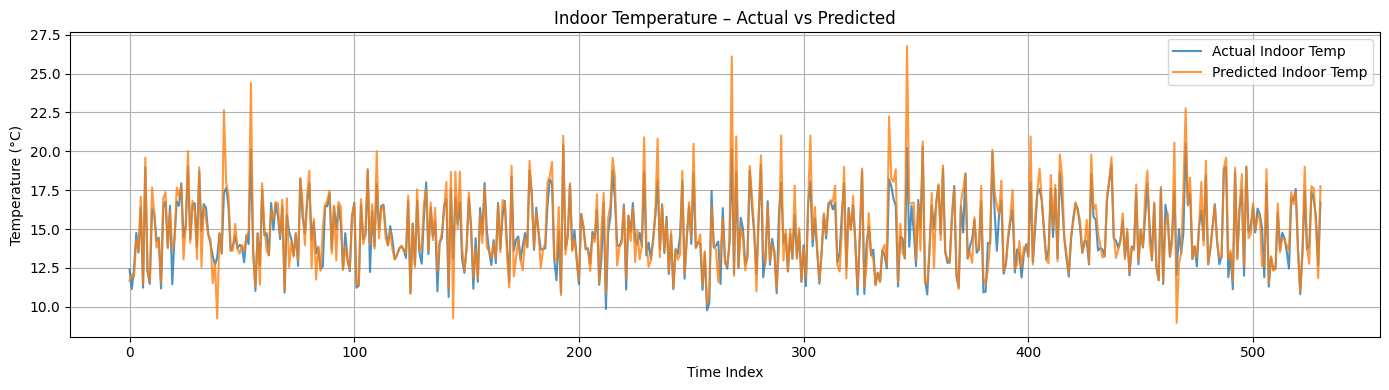

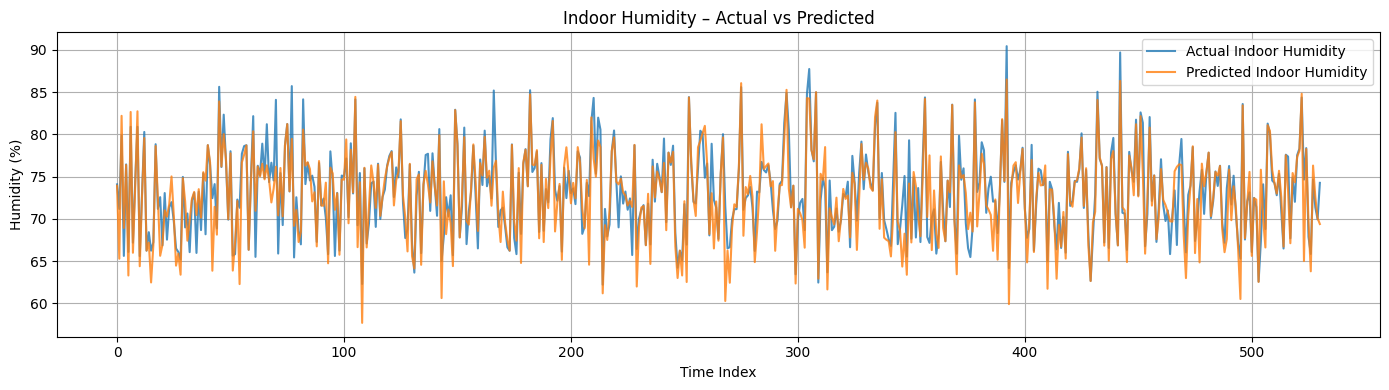

In [49]:
import matplotlib.pyplot as plt

# Actual vs Predicted - Temperature
plt.figure(figsize=(14, 4))
plt.plot(y_test_multi['Indoor_Temp'].values, label='Actual Indoor Temp', alpha=0.8)
plt.plot(test_preds[:, 0], label='Predicted Indoor Temp', alpha=0.8)
plt.title('Indoor Temperature – Actual vs Predicted')
plt.xlabel('Time Index')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Actual vs Predicted - Humidity
plt.figure(figsize=(14, 4))
plt.plot(y_test_multi['Indoor_Humidity'].values, label='Actual Indoor Humidity', alpha=0.8)
plt.plot(test_preds[:, 1], label='Predicted Indoor Humidity', alpha=0.8)
plt.title('Indoor Humidity – Actual vs Predicted')
plt.xlabel('Time Index')
plt.ylabel('Humidity (%)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
